# Demo residual analysis

The residual a demo dataset implies for one base model: at every demo frame, the action the demo executed minus the
action the base takes there (residual = executed - base, in the env's action space, the additive residual's meaning).

The base's actions are recomputed offline (no sim) the way the env runs the base and as `scripts/make_raw_demos.py`
does: a cold plan from its own observation history at frames 0, H, 2H, ..., each frame taking the plan's next action.
The base is stochastic, so the sample depends on `SEED`; the result is cached in `data_analysis/cache/`.

Cells: 1 imports, 2 variables, 3 load (dataset + model -> base actions), 4 processing, then one plot per cell, each
with its own variables. Figures are saved to `SAVE_DIR` as `{plot_type}_{dataset_name}_{model_name}_{action}.{png,svg}`
(`{action}` the action's name from `ACTION_NAMES`, or `all` for the figure with every action).

In [115]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from omegaconf import OmegaConf

# the repo root, so the base is loaded and planned by the project's own code
REPO = Path.cwd().resolve()
while not (REPO / "my_project").is_dir():
    if REPO.parent == REPO:
        raise RuntimeError("run this notebook from inside the hybrid_demos repo")
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from robonuke_rl_core.evaluation import resolved_config_path  # noqa: E402

from my_project.raw_demos import base_plan_actions, executed_abs_actions, frame_infos, success_frame  # noqa: E402
from my_project.wrappers.residual_policy.base_policy import load_base_policy  # noqa: E402
from my_project.wrappers.pose_math import mat_to_rot, rot_to_mat  # noqa: E402

In [116]:
# the task: an entry of data_analysis/residual_plots/models.yaml, which gives the demo dataset, the base model (its BC
# run and checkpoint) and, for a FurnitureBench phase alone (e.g. furniture_one_leg_insert), the phase ids kept
TASK_NAME = "robomimic_can"
MODELS_YAML = REPO / "data_analysis" / "residual_plots" / "models.yaml"

models = OmegaConf.load(MODELS_YAML)
if TASK_NAME not in models:
    raise KeyError(f"{TASK_NAME!r} is not in {MODELS_YAML}; its entries: {list(models)}")
model_entry = models[TASK_NAME]
DATASET = REPO / model_entry.dataset  # a LeRobot dataset folder (meta/episodes.jsonl + data/**/*.parquet)
MODEL_RUN = REPO / model_entry.model_run  # a BC run directory (checkpoints/; resolved_config.yaml in it or its parent)
MODEL_CHECKPOINT = model_entry.model_checkpoint
# FurnitureBench only: the phase ids kept (eval_state/phase/id: 0 corner, 1 grasp, 2 insert, 3 screw); None every frame
PHASES = None if model_entry.phases is None else list(model_entry.phases)
print(f"{TASK_NAME}: {model_entry.dataset}, {model_entry.model_run} ({MODEL_CHECKPOINT}), phases {PHASES}; "
      f"base {model_entry.status}, best BC success {model_entry.base_success_rate}, action_dim {model_entry.action_dim}")
if model_entry.status != "finished":
    print(f"note: {TASK_NAME}'s base is {model_entry.status}: its checkpoint is the best so far, or not there yet")

# the names in the saved files' names; None: the dataset's / run directory's folder name
DATASET_NAME = None
MODEL_NAME = None

# the base's planning, as the residual runs set it (base_policy.*); None keeps the model's own. The plans here are
# cold (each from pure noise), so BASE_WARM_START must end up False
BASE_ACTION_HORIZON = None
BASE_INFERENCE_STEPS = None
BASE_WARM_START = False

# the dataset's columns; None: the model's own bc.obs_key / bc.action_key
OBS_KEY = None
ACTION_KEY = None

# the base's sample is stochastic: its seed; and where it runs
SEED = 0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# the action, from the task's entry: a rot6d rotation's columns [start, stop) (FurnitureBench's action.abs: [3, 9]),
# replaced by roll, pitch, yaw (rad; R = Rz(yaw) Ry(pitch) Rx(roll), the repo's pose_math convention) in the base and
# executed actions, their residual wrapped to (-pi, pi]; None: the action as it is
ROT6D_COLUMNS = None if model_entry.rot6d_columns is None else list(model_entry.rot6d_columns)
# the base and executed actions relative to the robot's current state (the observation's), from the task's entry:
# poses (per hand: target - hand position; R_target R_hand^T, world axes) and fingers (the change in target: command -
# the previous step's executed command);
# models.yaml's header has the details. None: the actions as they are
RELATIVE_TO_EE = None if model_entry.get("relative_to_ee") is None else OmegaConf.to_container(model_entry.relative_to_ee)
# one entry per action column, in order (after the rot6d conversion, if any): its name, its size in plot units per
# action unit, its plot unit
euler = "_euler" if ROT6D_COLUMNS is not None else ""
ACTION_NAMES = list(model_entry[f"action_names{euler}"])
ACTION_SCALE = [float(s) for s in model_entry[f"action_scale{euler}"]]
ACTION_UNITS = list(model_entry[f"action_units{euler}"])
# each action's colour in every plot, by its name without the arm (right_x and left_x both red); a name not listed
# gets the next of matplotlib's tab10 colours
COLOUR_BY_NAME = {
    "x": "#d62728", "y": "#2ca02c", "z": "#1f77b4",
    "rx": "#ff7f0e", "ry": "#9467bd", "rz": "#17becf",
    "roll": "#ff7f0e", "pitch": "#9467bd", "yaw": "#17becf",
    "gripper": "#7f7f7f",
    "pinky": "#8c564b", "ring": "#e377c2", "middle": "#bcbd22", "index": "#aec7e8",
    "thumb_bend": "#393b79", "thumb_rot": "#637939",
}
_spare = iter(plt.get_cmap("tab10").colors)
ACTION_COLOURS = [COLOUR_BY_NAME.get(n.removeprefix("right_").removeprefix("left_")) or next(_spare) for n in ACTION_NAMES]

# the action dimensions plotted (indices); None: all
PLOT_DIMS = [0,1,2,3,4,5]

# where the figures go, and as what
SAVE_DIR = REPO / "data_analysis" / "residual_plots" / TASK_NAME
SAVE_FORMATS = ["png", "svg"]

# the base actions computed here are cached (git-ignored); a cached result is not recomputed
CACHE_DIR = REPO / "data_analysis" / "cache" / "demo_residuals"

# the figures
DPI = 150
FONT_SIZE = 11
SUBPLOT_SIZE = (4.5, 3.8)  # inches per subplot
N_COLS = 3  # subplots per row in the figure with every action

robomimic_can: data/robomimic_can_mh_300, runs/robomimic_can/bc_resfit_can/bc_resfit_can_a0 (actor_chkpt_best_success_rate.pt), phases None; base finished, best BC success 0.8, action_dim 7


In [117]:
dataset = Path(DATASET).expanduser().resolve()
run_dir = Path(MODEL_RUN).expanduser().resolve()
dataset_name = DATASET_NAME or dataset.name + ("" if PHASES is None else "_phase" + "-".join(str(int(p)) for p in PHASES))
model_name = MODEL_NAME or run_dir.name
bc = OmegaConf.load(resolved_config_path(run_dir)).bc
obs_key, action_key = OBS_KEY or str(bc.obs_key), ACTION_KEY or str(bc.action_key)

# the demo episodes: observations and the executed actions up to the success frame
with open(dataset / "meta" / "episodes.jsonl") as f:
    listed = [json.loads(line) for line in f]
episodes, skipped = [], []
for entry in listed:
    frame = pd.read_parquet(dataset / entry["file"])
    states = torch.tensor(np.stack(frame[obs_key].values), dtype=torch.float32)
    labels = torch.tensor(np.stack(frame[action_key].values), dtype=torch.float32)
    if entry.get("success_frame") is not None:  # robomimic / DexMimicGen: the dataset's actions are the executed ones
        T = int(entry["success_frame"]) + 1
        actions = labels
        phase = None
    elif entry.get("source"):  # FurnitureBench: the source pkl's success termination and executed actions
        from my_project.demos.furniture import load_pkl

        data = load_pkl(Path(entry["source"]))
        if not any(data["termination_terms"]["success"]):
            skipped.append((entry["file"], "no success"))
            continue
        T = success_frame(data) + 1
        actions = executed_abs_actions(Path(entry["source"]), states, labels)
        phase = frame_infos(data, T).get("eval_state/phase/id") if PHASES is not None else None
    else:
        raise ValueError(f"{entry['file']}: episodes.jsonl names neither a success_frame nor a source pkl for it")
    if PHASES is not None and phase is None:
        raise ValueError(f"{entry['file']}: PHASES is set, but the episode has no phase tag (eval_state/phase/id: a "
                         "FurnitureBench source pkl with env data)")
    episodes.append({"file": entry["file"], "states": states[:T], "actions": actions[:T],
                     "phase": None if phase is None else phase[:T].round().long()})
if not episodes:
    raise ValueError(f"{dataset}: no usable episodes (skipped {skipped})")
print(f"{dataset_name}: {len(episodes)} episodes, {sum(len(e['states']) for e in episodes)} frames, skipped {skipped}")

# the base's action at every frame, computed once per (dataset, model, planning, seed) and cached
policy = load_base_policy(run_dir, MODEL_CHECKPOINT, DEVICE)
if BASE_ACTION_HORIZON is not None:
    policy.action_horizon = int(BASE_ACTION_HORIZON)
if BASE_INFERENCE_STEPS is not None:
    policy.cfg.inference_steps = int(BASE_INFERENCE_STEPS)
if BASE_WARM_START is not None:
    policy.cfg.warm_start = bool(BASE_WARM_START)
if policy.cfg.warm_start:
    raise ValueError("the base plans here cold (each chunk from pure noise); set BASE_WARM_START = False")
key = {"dataset": str(dataset), "run": str(run_dir), "checkpoint": MODEL_CHECKPOINT, "obs_key": obs_key,
       "action_horizon": int(policy.action_horizon), "inference_steps": int(policy.cfg.inference_steps),
       "frames": [len(e["states"]) for e in episodes], "seed": SEED}
cache = CACHE_DIR / f"{dataset_name}_{model_name}_{hashlib.sha1(json.dumps(key).encode()).hexdigest()[:12]}.pt"
if cache.is_file():
    base_actions = torch.load(cache, weights_only=False)["base_actions"]
    print(f"base actions from the cache {cache.name}")
else:
    torch.manual_seed(SEED)
    base_actions = [base_plan_actions(policy, e["states"].to(DEVICE)).cpu() for e in episodes]
    cache.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"key": key, "base_actions": base_actions}, cache)
    print(f"base actions computed on {DEVICE} and cached to {cache.name}")
print(f"model {model_name} ({MODEL_CHECKPOINT}): action horizon {policy.action_horizon}, "
      f"{policy.cfg.inference_steps} inference steps")

robomimic_can_mh_300: 300 episodes, 61548 frames, skipped []
base actions from the cache robomimic_can_mh_300_bc_resfit_can_a0_ea889ead665d.pt
model bc_resfit_can_a0 (actor_chkpt_best_success_rate.pt): action horizon 8, 16 inference steps


In [118]:
# every frame of every episode, in plot units: the base's action, the executed one, the residual = executed - base
base = torch.cat(base_actions).double()
executed = torch.cat([e["actions"] for e in episodes]).double()
euler_columns = []
ee_R = None  # a rot6d hand's rotation, removed in the rot6d -> roll, pitch, yaw conversion below
if RELATIVE_TO_EE is not None:  # relative to the robot's current state (the observation's)
    states = torch.cat([e["states"] for e in episodes]).double()
    for pose in RELATIVE_TO_EE.get("poses") or []:
        action_pos, obs_pos = slice(*pose["action_pos"]), slice(*pose["obs_pos"])
        base[:, action_pos] -= states[:, obs_pos]  # target - the hand's position
        executed[:, action_pos] -= states[:, obs_pos]
        if pose.get("action_rot") is None:
            continue
        hand_R = rot_to_mat(states[:, slice(*pose["obs_rot"])], pose["obs_rot_param"])
        if pose.get("obs_rot_offset") is not None:  # the observed frame -> the target's frame
            hand_R = hand_R @ torch.tensor(pose["obs_rot_offset"], dtype=hand_R.dtype)
        action_rot, param = slice(*pose["action_rot"]), pose["action_rot_param"]
        if param == "rot6d":
            if ROT6D_COLUMNS is None or slice(*ROT6D_COLUMNS) != action_rot:
                raise ValueError(f"a rot6d hand rotation {pose['action_rot']} needs ROT6D_COLUMNS to be the same columns")
            ee_R = hand_R
        else:  # R_target R_hand^T, back in the action's own parametrisation
            for a in (base, executed):
                a[:, action_rot] = mat_to_rot(rot_to_mat(a[:, action_rot], param) @ hand_R.transpose(-1, -2), param)
    fingers = [int(c) for c in RELATIVE_TO_EE.get("fingers") or []]
    if fingers:  # the change in target: the command - the target the servo holds (the previous executed command)
        held = torch.cat([torch.cat([torch.zeros_like(e["actions"][:1]), e["actions"][:-1]]) for e in episodes]).double()
        base[:, fingers] -= held[:, fingers]
        executed[:, fingers] -= held[:, fingers]
if ROT6D_COLUMNS is not None:  # the rot6d columns -> roll, pitch, yaw (rad); relative: of R R_ee^T
    start, stop = (int(c) for c in ROT6D_COLUMNS)
    if stop - start != 6:
        raise ValueError(f"ROT6D_COLUMNS {ROT6D_COLUMNS} span {stop - start} columns; rot6d is 6")
    def to_euler(a):
        R = rot_to_mat(a[:, start:stop], "rot6d")
        if ee_R is not None:
            R = R @ ee_R.transpose(-1, -2)
        return torch.cat([a[:, :start], mat_to_rot(R, "euler"), a[:, stop:]], dim=1)
    base, executed = to_euler(base), to_euler(executed)
    euler_columns = [start, start + 1, start + 2]
base, executed = base.numpy(), executed.numpy()
action_dim = base.shape[1]
for name, values in [("ACTION_NAMES", ACTION_NAMES), ("ACTION_COLOURS", ACTION_COLOURS), ("ACTION_SCALE", ACTION_SCALE),
                     ("ACTION_UNITS", ACTION_UNITS)]:
    if len(values) != action_dim:
        raise ValueError(f"{name} has {len(values)} entries; the action has {action_dim} dimensions")
scale = np.asarray(ACTION_SCALE, dtype=np.float64)
if PHASES is not None:  # only the frames of the chosen phases (the base planned over whole episodes)
    keep = torch.isin(torch.cat([e["phase"] for e in episodes]), torch.tensor([int(p) for p in PHASES])).numpy()
    base, executed = base[keep], executed[keep]
    print(f"phases {list(PHASES)}: {int(keep.sum())} of {len(keep)} frames")
residual = executed - base
residual[:, euler_columns] = (residual[:, euler_columns] + np.pi) % (2 * np.pi) - np.pi  # angles: the short way round
base, executed, residual = base * scale, executed * scale, residual * scale
dims = list(range(action_dim)) if PLOT_DIMS is None else [int(d) for d in PLOT_DIMS]

summary = pd.DataFrame({
    "unit": ACTION_UNITS,
    "|base| mean": np.abs(base).mean(0),
    "|residual| mean": np.abs(residual).mean(0),
    "|residual| p95": np.quantile(np.abs(residual), 0.95, axis=0),
    "residual std": residual.std(0),
}, index=ACTION_NAMES).round(3)
print(f"{len(base)} frames")
display(summary)


def x_values(d, x_mode):
    """The base action of dimension d: its value or its magnitude."""
    if x_mode == "value":
        return base[:, d]
    if x_mode == "magnitude":
        return np.abs(base[:, d])
    raise ValueError(f"x mode {x_mode!r}: 'value' or 'magnitude'")


def x_label(d, x_mode):
    name, unit = ACTION_NAMES[d], ACTION_UNITS[d]
    return f"base {name} ({unit})" if x_mode == "value" else f"|base {name}| ({unit})"


def figure(n):
    """A figure of n subplots (N_COLS per row) and its axes, the unused ones hidden."""
    cols = min(n, N_COLS)
    rows = -(-n // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(SUBPLOT_SIZE[0] * cols, SUBPLOT_SIZE[1] * rows), dpi=DPI,
                             squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, list(axes.flat[:n])


def save(fig, plot_type, action):
    """fig as SAVE_DIR/{plot_type}_{dataset_name}_{model_name}_{action}.{format}, every SAVE_FORMATS."""
    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    for fmt in SAVE_FORMATS:
        path = SAVE_DIR / f"{plot_type}_{dataset_name}_{model_name}_{action}.{fmt}"
        fig.savefig(path, bbox_inches="tight")
        print(f"saved {path}")


def draw(plot_type, panel, save_mode, title):
    """Every plotted dimension through panel(ax, d): one figure with all of them ('combined'), one figure per
    dimension ('separate'), or both; each figure shown and saved."""
    if save_mode not in ("combined", "separate", "both"):
        raise ValueError(f"save mode {save_mode!r}: 'combined', 'separate' or 'both'")
    with plt.rc_context({"font.size": FONT_SIZE}):
        if save_mode in ("combined", "both"):
            fig, axes = figure(len(dims))
            for ax, d in zip(axes, dims):
                panel(ax, d)
            fig.suptitle(title)
            fig.tight_layout()
            save(fig, plot_type, "all")
            plt.show()
        if save_mode in ("separate", "both"):
            for d in dims:
                fig, (ax,) = figure(1)
                panel(ax, d)
                fig.tight_layout()
                save(fig, plot_type, ACTION_NAMES[d])
                plt.show()

61548 frames


,unit,|base| mean,|residual| mean,|residual| p95,residual std
x,mm,9.193,3.466,11.241,5.774
y,mm,17.143,3.865,13.598,6.546
z,mm,9.947,4.221,13.055,6.526
rx,deg,0.608,0.201,0.582,0.358
ry,deg,1.017,0.282,0.833,0.503
rz,deg,1.777,0.294,0.860,0.633
gripper,unit,0.993,0.061,0.020,0.330


saved /home/hunter/hybrid_demos/data_analysis/residual_plots/robomimic_can/scatter-value_robomimic_can_mh_300_bc_resfit_can_a0_all.png
saved /home/hunter/hybrid_demos/data_analysis/residual_plots/robomimic_can/scatter-value_robomimic_can_mh_300_bc_resfit_can_a0_all.svg


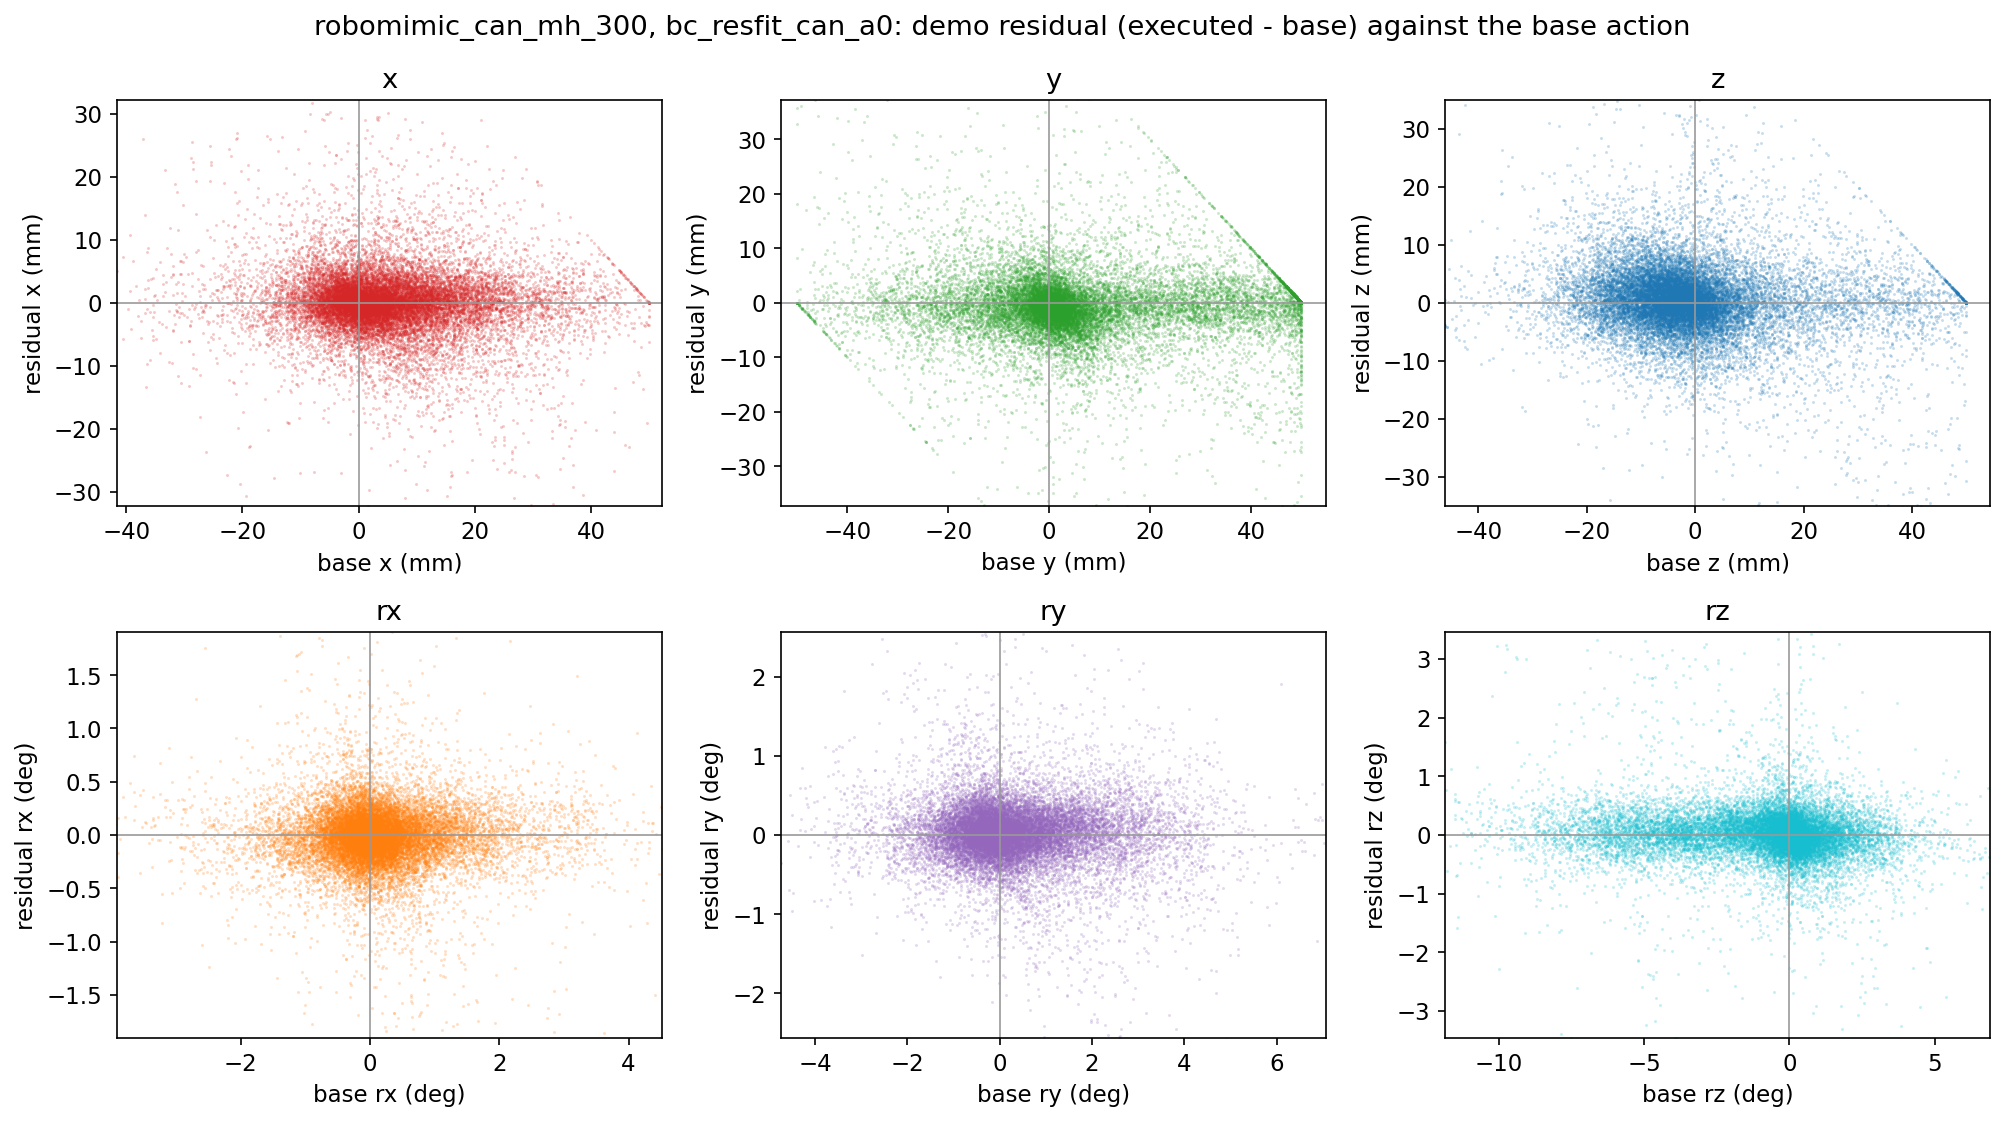

In [119]:
# the residual against the base action, one subplot per action dimension
X_MODE = "value"  # "value": the base action's signed value; "magnitude": its absolute value
SAVE_MODE = "combined"  # "combined": one figure with every action; "separate": one figure per action; "both"
MAX_POINTS = 20000  # points drawn per subplot, a random subset when there are more (None: all)
POINT_SIZE = 2
ALPHA = 0.25
AXIS_QUANTILE = 0.995  # the axes span this quantile of the points (1.0: all of them)

rng = np.random.default_rng(SEED)
shown = rng.permutation(len(base))[:MAX_POINTS] if MAX_POINTS else np.arange(len(base))


def scatter_panel(ax, d):
    x, y = x_values(d, X_MODE), residual[:, d]
    ax.scatter(x[shown], y[shown], s=POINT_SIZE, alpha=ALPHA, color=ACTION_COLOURS[d], rasterized=True, linewidths=0)
    if X_MODE == "value":
        lo, hi = np.quantile(x, [(1 - AXIS_QUANTILE) / 2, (1 + AXIS_QUANTILE) / 2])
        pad = 0.05 * (hi - lo)
        ax.set_xlim(lo - pad, hi + pad)
        ax.axvline(0, color="0.6", lw=0.8)
    else:
        ax.set_xlim(0, np.quantile(x, AXIS_QUANTILE) * 1.05)
    top = np.quantile(np.abs(y), AXIS_QUANTILE) * 1.1
    ax.set_ylim(-top, top)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xlabel(x_label(d, X_MODE))
    ax.set_ylabel(f"residual {ACTION_NAMES[d]} ({ACTION_UNITS[d]})")
    ax.set_title(ACTION_NAMES[d])


draw(f"scatter-{X_MODE}", scatter_panel, SAVE_MODE,
     f"{dataset_name}, {model_name}: demo residual (executed - base) against the base action")

saved /home/hunter/hybrid_demos/data_analysis/residual_plots/robomimic_can/std-magnitude_robomimic_can_mh_300_bc_resfit_can_a0_all.png
saved /home/hunter/hybrid_demos/data_analysis/residual_plots/robomimic_can/std-magnitude_robomimic_can_mh_300_bc_resfit_can_a0_all.svg


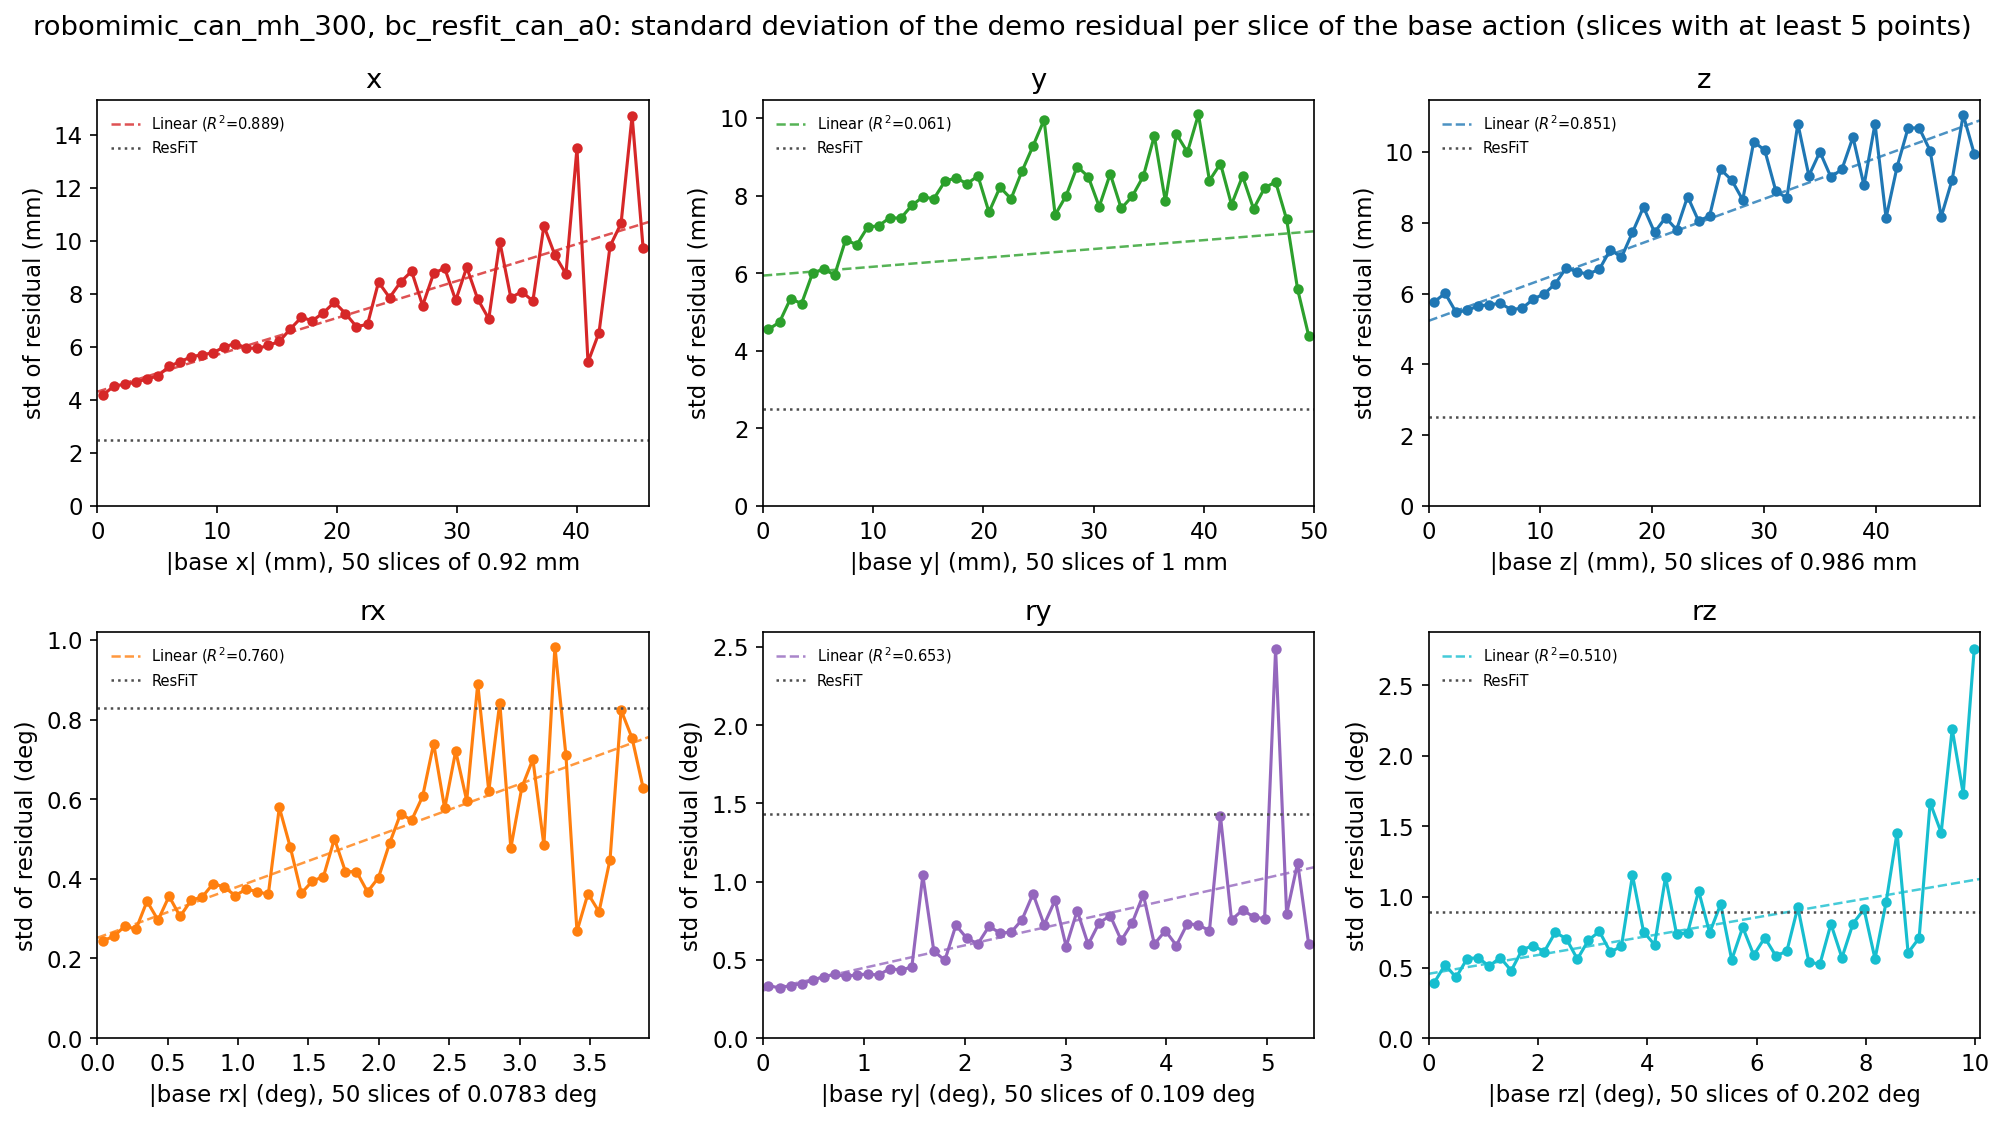

degree-1 fit of the slices' std against magnitude (weighted by count)


,x^1,x^0,R²,slices fitted
x,0.13919,4.311211,0.889338,50 of 50
y,0.022857,5.936089,0.061311,50 of 50
z,0.114919,5.22686,0.851333,50 of 50
rx,0.128659,0.251933,0.759664,50 of 50
ry,0.144145,0.304353,0.652765,50 of 50
rz,0.066637,0.455539,0.509768,50 of 50


In [ ]:
# the spread of the residual in vertical slices of the base action, one subplot per action dimension
X_MODE = "magnitude"  # "value": the base action's signed value; "magnitude": its absolute value
STAT = "std"  # "variance" or "std" (standard deviation) of the residuals in each slice
NUM_BINS = 50  # slices, equal width, over the x range below
X_RANGE_QUANTILE = 0.995  # the slices span this quantile of the base action (1.0: all of it); points past it are left out
MIN_POINTS = 5  # a slice with fewer points is not drawn
SHOW_COUNTS = False  # the number of points over each slice's marker
SAVE_MODE = "combined"  # "combined": one figure with every action; "separate": one figure per action; "both"
FIT = True  # fit a polynomial to each subplot's slice points, drawn dashed, its R² in the legend and the table below
FIT_DEGREE = None  # the polynomial's degree; None: 1 for "std" (linear), 2 for "variance" (quadratic)
FIT_WEIGHTED = True  # weight each slice by its number of points (the fit and its R²); False: every slice the same
FIT_VERTEX_AT_ZERO = True  # a quadratic's low point at x = 0: y = a x^2 + c with a >= 0 (no x term); c is free
# slices of the NUM_BINS left out of the fit (and its R²) at the start and the end of the x range, e.g. (1, 1) with
# X_MODE "value" or (0, 1) with "magnitude" to leave out the slices whose spread a motor or env limit squeezes; they
# are still drawn, hollow. (0, 0): every slice
FIT_TRIM_BINS = (0, 0)
SIGMA_LINE = True  # a flat line at SIGMA_SCALE x sigma, sigma the half range (max - min) / 2 of the demo actions on the
# dimension (in plot units, after the relative and scale steps); squared, (SIGMA_SCALE sigma)^2, when STAT is "variance"
SIGMA_SCALE = 0.05
SCALED_FIT = False  # with FIT: the fit line times SIGMA_SCALE (SIGMA_SCALE² when STAT is "variance"), dash-dot
ADAPTIVE_LINE = True  # SIGMA_SCALE x sigma x |b| / median(|b|), |b| the base action's magnitude (the x axis's, |x| with
# X_MODE "value"), the median the demo (executed) actions' magnitude's over every frame; squared when STAT is "variance"
LEGEND_LOC = "upper left"  # the legend's corner: "upper left", "upper right", "lower left", "lower right" (or "best")

if STAT not in ("variance", "std"):
    raise ValueError(f"STAT {STAT!r}: 'variance' or 'std'")
fit_degree = int(FIT_DEGREE) if FIT_DEGREE is not None else (1 if STAT == "std" else 2)
FIT_NAMES = {1: "Linear", 2: "Quadratic", 3: "Cubic"}  # the fit's legend name by its degree
fits = {}  # action name -> the fit's coefficients (highest power first) and R²
sigma = (executed.max(0) - executed.min(0)) / 2  # the demo actions' half range, per dimension
median_magnitude = np.median(np.abs(executed), axis=0)  # E(|b|): the demo (executed) actions' median magnitude, per dimension


def fit_slices(centres, values, counts):
    """The degree-fit_degree polynomial through the slice points and its R², both weighted by the slices' counts when
    FIT_WEIGHTED; None when there are not more points than coefficients. With FIT_VERTEX_AT_ZERO a quadratic is
    a x^2 + c with a >= 0, so its minimum is at x = 0 (the least-squares a, or 0 and c the mean when that a is negative)."""
    x, y = np.asarray(centres), np.asarray(values)
    w = np.asarray(counts, dtype=np.float64) if FIT_WEIGHTED else np.ones(len(x))
    vertex = FIT_VERTEX_AT_ZERO and fit_degree == 2
    powers = [2, 0] if vertex else list(range(fit_degree, -1, -1))
    if len(x) <= len(powers):
        return None
    sw = np.sqrt(w)
    solved, *_ = np.linalg.lstsq(np.stack([x ** p for p in powers], axis=1) * sw[:, None], y * sw, rcond=None)
    if vertex and solved[0] < 0:  # the constrained optimum is on the boundary a = 0: a flat line at the mean
        solved = np.array([0.0, np.average(y, weights=w)])
    coef = np.zeros(fit_degree + 1)  # every power, highest first, the dropped ones 0
    for p, c in zip(powers, solved):
        coef[fit_degree - p] = c
    mean = np.average(y, weights=w)
    ss_res = np.sum(w * (y - np.polyval(coef, x)) ** 2)
    ss_tot = np.sum(w * (y - mean) ** 2)
    return coef, (1.0 - ss_res / ss_tot) if ss_tot > 0 else float("nan")


def poly_text(coef):
    terms = []
    for p, c in zip(range(len(coef) - 1, -1, -1), coef):
        if c == 0 and p > 0:  # a term the fit leaves out (FIT_VERTEX_AT_ZERO)
            continue
        terms.append(f"{c:.3g}" + ("" if p == 0 else "x" if p == 1 else f"x^{p}"))
    return " + ".join(terms).replace("+ -", "- ")


def spread_panel(ax, d):
    x, y = x_values(d, X_MODE), residual[:, d]
    if X_MODE == "value":
        lo, hi = np.quantile(x, [(1 - X_RANGE_QUANTILE) / 2, (1 + X_RANGE_QUANTILE) / 2])
    else:
        lo, hi = 0.0, np.quantile(x, X_RANGE_QUANTILE)
    edges = np.linspace(lo, hi, NUM_BINS + 1)
    if hi <= lo:  # a constant base action: one slice holds it all
        edges = np.array([lo - 0.5, lo + 0.5])
    slice_of = np.digitize(x, edges[1:-1])  # 0 .. bins-1
    inside = (x >= edges[0]) & (x <= edges[-1])
    trim_start, trim_end = (int(n) for n in FIT_TRIM_BINS)
    centres, values, counts, fitted = [], [], [], []
    for k in range(len(edges) - 1):
        ys = y[inside & (slice_of == k)]
        if len(ys) >= MIN_POINTS:
            centres.append((edges[k] + edges[k + 1]) / 2)
            values.append(ys.var() if STAT == "variance" else ys.std())
            counts.append(len(ys))
            fitted.append(trim_start <= k < len(edges) - 1 - trim_end)  # not trimmed off either end
    fitted = np.asarray(fitted, dtype=bool)
    ax.plot(centres, values, "-", color=ACTION_COLOURS[d])
    ax.plot(np.asarray(centres)[fitted], np.asarray(values)[fitted], "o", color=ACTION_COLOURS[d], ms=4)
    ax.plot(np.asarray(centres)[~fitted], np.asarray(values)[~fitted], "o", mfc="white", mec=ACTION_COLOURS[d], ms=4)
    if SHOW_COUNTS:
        for c, v, n in zip(centres, values, counts):
            ax.annotate(str(n), (c, v), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=6, color="0.4")
    if FIT:
        keep = np.flatnonzero(fitted)
        fit = fit_slices([centres[i] for i in keep], [values[i] for i in keep], [counts[i] for i in keep])
        if fit is None:
            print(f"{ACTION_NAMES[d]}: {len(keep)} slices left after FIT_TRIM_BINS, too few for a degree-{fit_degree} fit")
        else:
            coef, r2 = fit
            fits[ACTION_NAMES[d]] = (coef, r2, f"{len(keep)} of {len(centres)}")
            xs = np.linspace(edges[0], edges[-1], 200)
            fit_name = FIT_NAMES.get(fit_degree, f"Degree {fit_degree}")
            ax.plot(xs, np.polyval(coef, xs), "--", color=ACTION_COLOURS[d], lw=1.2, alpha=0.8,
                    label=f"{fit_name} ($R^2$={r2:.3f})")
            if SCALED_FIT:  # the fit x SIGMA_SCALE (x SIGMA_SCALE² for variance, the same scaling of the std)
                factor = SIGMA_SCALE ** 2 if STAT == "variance" else SIGMA_SCALE
                ax.plot(xs, factor * np.polyval(coef, xs), "-.", color=ACTION_COLOURS[d], lw=1.2, alpha=0.8,
                        label=f"Scaled {fit_name}")
    if SIGMA_LINE:
        level = SIGMA_SCALE * sigma[d]
        if STAT == "variance":
            level = level ** 2
        ax.axhline(level, color="0.3", ls=":", lw=1.2, label="ResFiT")
    if ADAPTIVE_LINE:
        xs = np.linspace(edges[0], edges[-1], 200)
        level = SIGMA_SCALE * sigma[d] * np.abs(xs) / median_magnitude[d]
        if STAT == "variance":
            level = level ** 2
        ax.plot(xs, level, "-.", color="0.3", lw=1.2, label="Adaptive ResFiT")
    if FIT or SIGMA_LINE or ADAPTIVE_LINE:
        ax.legend(fontsize=7, loc=LEGEND_LOC, frameon=False)
    ax.set_xlim(edges[0], edges[-1])
    ax.set_ylim(bottom=0)
    unit = ACTION_UNITS[d]
    ax.set_xlabel(f"{x_label(d, X_MODE)}, {len(edges) - 1} slices of {edges[1] - edges[0]:.3g} {unit}")
    ax.set_ylabel(f"variance of residual ({unit}²)" if STAT == "variance" else f"std of residual ({unit})")
    ax.set_title(ACTION_NAMES[d])


draw(f"{STAT}-{X_MODE}", spread_panel, SAVE_MODE,
     f"{dataset_name}, {model_name}: {'variance' if STAT == 'variance' else 'standard deviation'} of the demo residual "
     f"per slice of the base action (slices with at least {MIN_POINTS} points)")
if FIT and fits:
    table = pd.DataFrame({name: {**{f"x^{p}": c for p, c in zip(range(fit_degree, -1, -1), coef)}, "R²": r2,
                                 "slices fitted": used} for name, (coef, r2, used) in fits.items()}).T
    print(f"degree-{fit_degree} fit of the slices' {STAT} against {X_MODE}" + (" (weighted by count)" if FIT_WEIGHTED else "")
          + (", low point at x = 0" if FIT_VERTEX_AT_ZERO and fit_degree == 2 else "")
          + (f", {FIT_TRIM_BINS[0]} slices trimmed at the start and {FIT_TRIM_BINS[1]} at the end" if any(FIT_TRIM_BINS) else ""))
    display(table.round(4))